# CNN Training - Exercise Binary Classification

Approach 1: binary classification (correct / incorrect) of the whole exercise image.

**Compared models**: EfficientNetV2-S, EfficientNetV2-M and ConvNeXt-Tiny, pre-trained on ImageNet, with fine-tuning of the classification head.

**Data**: all the labeled exercises of all batches.

**Validation**: 5-fold cross-validation grouped by student (StratifiedGroupKFold): all the exercises of a student are in the same fold, so the model is never tested on a handwriting it has seen. Same folds for all three models.

**Class imbalance handling**: automatically computed class weights

**Outputs**:
- `outputs/predictions/classifier.csv`: one row per copy and per model (student, exercise, label, verdict)
- `outputs/classifier/metrics.csv`: scores of each model, on all the data and on each subset (batch, exercise type)
- `outputs/classifier/`: training curves and confusion matrices
- `models/classifier_<model>.pth`: final model (not versioned)

## 1. Imports

In [9]:
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score, recall_score,
)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print(f"PyTorch: {torch.__version__}")

Device: cuda
PyTorch: 2.14.1+cu130


## 2. Configuration

In [10]:
# Output files
OUTPUT_DIR = Path("../../outputs/classifier")                         # figures and scores
PREDICTIONS_PATH = Path("../../outputs/predictions/classifier.csv")   # one row per copy and per model
MODELS_DIR = Path("../../models")                                     # final model weights (not versioned)
ANSWER_KEY_PATH = Path("../../config/answer_key.csv")                 # gives the type of each exercise

MODEL_NAMES = ["efficientnet_v2_s", "efficientnet_v2_m", "convnext_tiny"]    # CNN models used

# Hyperparameters
IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 30
LEARNING_RATE = 1e-3    # head only (phase 1), divided by 10 once the backbone is unfrozen (phase 2)
N_FOLDS = 5
SEED = 42
UNFREEZE_AT_EPOCH = 15  # unfreeze the last layers after this epoch

def set_seed(seed=SEED):
    torch.manual_seed(seed)
    np.random.seed(seed)

set_seed()

for folder in (OUTPUT_DIR, PREDICTIONS_PATH.parent, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

## 3. Loading the dataset

We load the tensors saved by `02_preprocessing.ipynb`. `X_exercise.npy` holds the preprocessed images, `y_exercise.npy` their labels (1 = correct, 0 = incorrect) and `names_exercise.npy` their file names.

From the file name we get the student (`set_2`, `b2_set_4`), the batch and the exercise. The exercise type (write a number, tick, colour...) comes from the answer key. They are only used to split the scores afterwards, the model never sees them.

In [11]:
X = np.load("../../data/processed/X_exercise.npy")
y = np.load("../../data/processed/y_exercise.npy")
names = np.load("../../data/processed/names_exercise.npy")

# Information about each copy, taken from its file name: "q01/correct/set_2_q01.jpg"
answer_key = pd.read_csv(ANSWER_KEY_PATH).set_index("exercise")
copies = pd.DataFrame({
    "student": [Path(n).stem.rsplit("_", 1)[0] for n in names],
    "exercise": [Path(n).stem.rsplit("_", 1)[1] for n in names],
})
copies["batch"] = np.where(copies["student"].str.startswith("b2_"), 2, 1)
copies["type"] = copies["exercise"].map(answer_key["type"])
copies["label"] = np.where(y == 1, "correct", "incorrect")
assert copies["type"].notna().all(), "exercise missing from the answer key"

print(f"Dataset shape : {X.shape}")
print(f"Correct : {np.sum(y == 1)}")
print(f"Incorrect : {np.sum(y == 0)}")
display(copies.groupby(["batch", "type"]).size().rename("copies").to_frame())

Dataset shape : (174, 224, 224, 3)
Correct : 107
Incorrect : 67


copies
batch type                
1     circle             5
      colour             5
      link              25
      tick              20
      write_number      80
2     colour            30
      trace              9

## 4. PyTorch dataset and augmentation

**Augmentation (training only)**: at each epoch, each image is slightly and randomly modified (rotation ±5°, brightness ±10%, slight noise).

The images are already normalised (ImageNet): we denormalise them back to [0, 1], apply the augmentation, then normalise again.

**Validation**: no augmentation, images are used as they are.

In [12]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def augment(img):
    """Rotation ±5°, brightness ±10%, slight noise on a normalised image (C,H,W)."""
    img = img * STD + MEAN  # back to [0, 1]
    img = transforms.functional.rotate(img, float(np.random.uniform(-5, 5)), fill=[1.0])  # corners filled with white
    img = img * np.random.uniform(0.9, 1.1)
    img = img + torch.randn_like(img) * 0.01
    img = img.clamp(0, 1)
    return (img - MEAN) / STD


class ExamDataset(Dataset):
    def __init__(self, X, y, augment=False):
        self.X = torch.tensor(X, dtype=torch.float32).permute(0, 3, 1, 2)  # (N,H,W,C) → (N,C,H,W)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.augment = augment
    
    def __len__(self):
        return len(self.y)
    
    def __getitem__(self, idx):
        img = self.X[idx]
        if self.augment:
            img = augment(img)
        return img, self.y[idx]

## 5. Models

Three models pre-trained on ImageNet. For each one, the last layer is replaced with the same binary classification head. ConvNeXt keeps its normalisation and its `Flatten` just before this head.

| Model | Parameters (approx.) | ImageNet training resolution |
|---|---|---|
| EfficientNetV2-S | 21 M | 384 px |
| EfficientNetV2-M | 54 M | 480 px |
| ConvNeXt-Tiny | 29 M | 224 px |

Here, all three receive 224×224 images.

**Fine-tuning strategy**:
1. Freeze the whole backbone (pre-trained features)
2. Train only the classification head
3. After a few epochs, unfreeze the last layers of the backbone to refine

In [13]:
MODELS = {
    "efficientnet_v2_s": (models.efficientnet_v2_s, models.EfficientNet_V2_S_Weights.IMAGENET1K_V1),
    "efficientnet_v2_m": (models.efficientnet_v2_m, models.EfficientNet_V2_M_Weights.IMAGENET1K_V1),
    "convnext_tiny": (models.convnext_tiny, models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1),
}


def binary_head(in_features):
    return [
        nn.Dropout(0.3),
        nn.Linear(in_features, 128),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(128, 1),
    ]


def create_model(model_name, unfreeze_last_n=0):
    """Creates the requested model with a binary classification head."""
    builder, weights = MODELS[model_name]
    model = builder(weights=weights)

    # Freeze the backbone
    for param in model.features.parameters():
        param.requires_grad = False

    # Unfreeze the last N blocks if requested
    if unfreeze_last_n > 0:
        for param in model.features[-unfreeze_last_n:].parameters():
            param.requires_grad = True

    # New classification head
    in_features = model.classifier[-1].in_features
    if model_name.startswith("convnext"):
        # Keep LayerNorm2d and Flatten, required before the linear layer
        model.classifier = nn.Sequential(*model.classifier[:-1], *binary_head(in_features))
    else:
        model.classifier = nn.Sequential(*binary_head(in_features))

    return model.to(device)

# Test
for name in MODEL_NAMES:
    model_test = create_model(name)
    trainable = sum(p.numel() for p in model_test.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model_test.parameters())
    print(f"{name} : {trainable:,} / {total:,} trainable parameters ({trainable/total*100:.1f}%)")
    del model_test

efficientnet_v2_s : 164,097 / 20,341,585 trainable parameters (0.8%)
efficientnet_v2_m : 164,097 / 53,022,453 trainable parameters (0.3%)
convnext_tiny : 100,097 / 27,918,689 trainable parameters (0.4%)


## 6. Training and evaluation functions

In [14]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(imgs).squeeze(1)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * imgs.size(0)
        preds = (torch.sigmoid(outputs) > 0.5).float()
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    
    return total_loss / total, correct / total


def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs).squeeze(1)
            loss = criterion(outputs, labels)
            
            total_loss += loss.item() * imgs.size(0)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    acc = (all_preds == all_labels).mean()
    
    return total_loss / len(all_labels), acc, all_preds, all_labels

## 7. Training with K-Fold Cross Validation

The same procedure is applied to each model, with **the same folds**: scores can therefore be compared fold by fold.

For each fold:
1. Phase 1 (epochs 1-15): backbone frozen, only the head is trained (learning rate 1e-3)
2. Phase 2 (epochs 16-30): the last 2 blocks of the backbone are unfrozen to refine (learning rate 1e-4)

Class weights compensate for the correct/incorrect imbalance.

The score of a fold is that of the model **at the last epoch**, and the learning rate does not depend on validation. The validation fold is therefore only used to measure, never to choose: otherwise the score would be optimistic. This is also exactly the procedure of the final model (section 11).

The fold models are not saved, they are only used to measure the score.

In [15]:
# Class weights for the imbalance
n_correct = np.sum(y == 1)
n_incorrect = np.sum(y == 0)
weight_for_incorrect = len(y) / (2 * n_incorrect)
weight_for_correct = len(y) / (2 * n_correct)

print(f"Class weights: correct={weight_for_correct:.2f}, incorrect={weight_for_incorrect:.2f}")
print(f"(the minority class has a higher weight)")

Class weights: correct=0.81, incorrect=1.30
(the minority class has a higher weight)


In [16]:
# Student of each image: "set_2", "b2_set_2"
students = copies["student"].to_numpy()
print(f"{len(np.unique(students))} students")

# Folds grouped by student: a student is never in train and validation at the same time
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLDS = list(sgkf.split(X, y, groups=students))  # same folds for all models
for i, (train_idx, val_idx) in enumerate(FOLDS):
    print(f"Fold {i+1}: val students = {sorted(set(students[val_idx]))}")


def compute_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_incorrect": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
    }


def make_criterion():
    # pos_weight applies to class 1 = correct: < 1 if correct is the majority class, > 1 otherwise
    pos_weight = torch.tensor([weight_for_correct / weight_for_incorrect]).to(device)
    return nn.BCEWithLogitsLoss(pos_weight=pos_weight)


def run_kfold(model_name):
    """Trains and evaluates a model on all folds."""
    set_seed()  # each model starts from the same random state

    fold_metrics = []
    all_fold_preds = np.zeros(len(y))
    histories = []

    for fold, (train_idx, val_idx) in enumerate(FOLDS):
        print(f"\n{'='*50}")
        print(f"{model_name} - FOLD {fold + 1}/{N_FOLDS}")
        print(f"Train: {len(train_idx)} | Val: {len(val_idx)}")

        # Datasets
        train_ds = ExamDataset(X[train_idx], y[train_idx], augment=True)
        val_ds = ExamDataset(X[val_idx], y[val_idx])

        train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
        val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

        # Model (backbone frozen at the start)
        model = create_model(model_name, unfreeze_last_n=0)
        criterion = make_criterion()
        optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LEARNING_RATE)

        history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

        for epoch in range(EPOCHS):
            # Phase 2: unfreeze the last layers
            if epoch == UNFREEZE_AT_EPOCH:
                print(f"  → Unfreezing the last 2 backbone blocks")
                for param in model.features[-2:].parameters():
                    param.requires_grad = True
                optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LEARNING_RATE * 0.1)

            train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
            val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)

            history["train_loss"].append(train_loss)
            history["val_loss"].append(val_loss)
            history["train_acc"].append(train_acc)
            history["val_acc"].append(val_acc)

            if (epoch + 1) % 5 == 0 or epoch == 0:
                print(f"  Epoch {epoch+1:2d}/{EPOCHS} | "
                      f"Train loss: {train_loss:.4f} acc: {train_acc:.3f} | "
                      f"Val loss: {val_loss:.4f} acc: {val_acc:.3f}")

        # Final evaluation of the fold with the last-epoch model
        _, _, preds, _ = evaluate(model, val_loader, criterion)

        all_fold_preds[val_idx] = preds
        fold_metrics.append(compute_metrics(y[val_idx], preds))
        histories.append(history)

        print(f"  Val accuracy: {fold_metrics[-1]['accuracy']:.3f} | F1 macro: {fold_metrics[-1]['f1_macro']:.3f}")

        # Free memory before the next fold
        del model, optimizer
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return {"fold_metrics": fold_metrics, "preds": all_fold_preds, "histories": histories}


results = {}
for name in MODEL_NAMES:
    results[name] = run_kfold(name)
    accs = [m["accuracy"] for m in results[name]["fold_metrics"]]
    print(f"\n{name}: mean accuracy {np.mean(accs):.3f} ± {np.std(accs):.3f}")

15 students
Fold 1: val students = ['b2_set_2', 'b2_set_3', 'b2_set_5', 'b2_set_9']
Fold 2: val students = ['b2_set_10', 'b2_set_6', 'set_1']
Fold 3: val students = ['b2_set_4', 'set_2']
Fold 4: val students = ['b2_set_1', 'b2_set_7', 'b2_set_8']
Fold 5: val students = ['set_3', 'set_4', 'set_5']

efficientnet_v2_s - FOLD 1/5
Train: 158 | Val: 16
  Epoch  1/30 | Train loss: 0.5279 acc: 0.601 | Val loss: 0.5738 acc: 0.625
  Epoch  5/30 | Train loss: 0.4628 acc: 0.734 | Val loss: 0.5296 acc: 0.562
  Epoch 10/30 | Train loss: 0.4510 acc: 0.658 | Val loss: 0.5881 acc: 0.438
  Epoch 15/30 | Train loss: 0.4602 acc: 0.677 | Val loss: 0.6541 acc: 0.438
  → Unfreezing the last 2 backbone blocks
  Epoch 20/30 | Train loss: 0.3686 acc: 0.766 | Val loss: 0.7320 acc: 0.562
  Epoch 25/30 | Train loss: 0.3117 acc: 0.842 | Val loss: 0.7787 acc: 0.562
  Epoch 30/30 | Train loss: 0.2421 acc: 0.892 | Val loss: 1.0449 acc: 0.562
  Val accuracy: 0.562 | F1 macro: 0.360

efficientnet_v2_s - FOLD 2/5
Train: 

## 8. Training curves

Loss and accuracy for each fold and each model. We check that there is no overfitting (train going up while val stagnates or goes down).

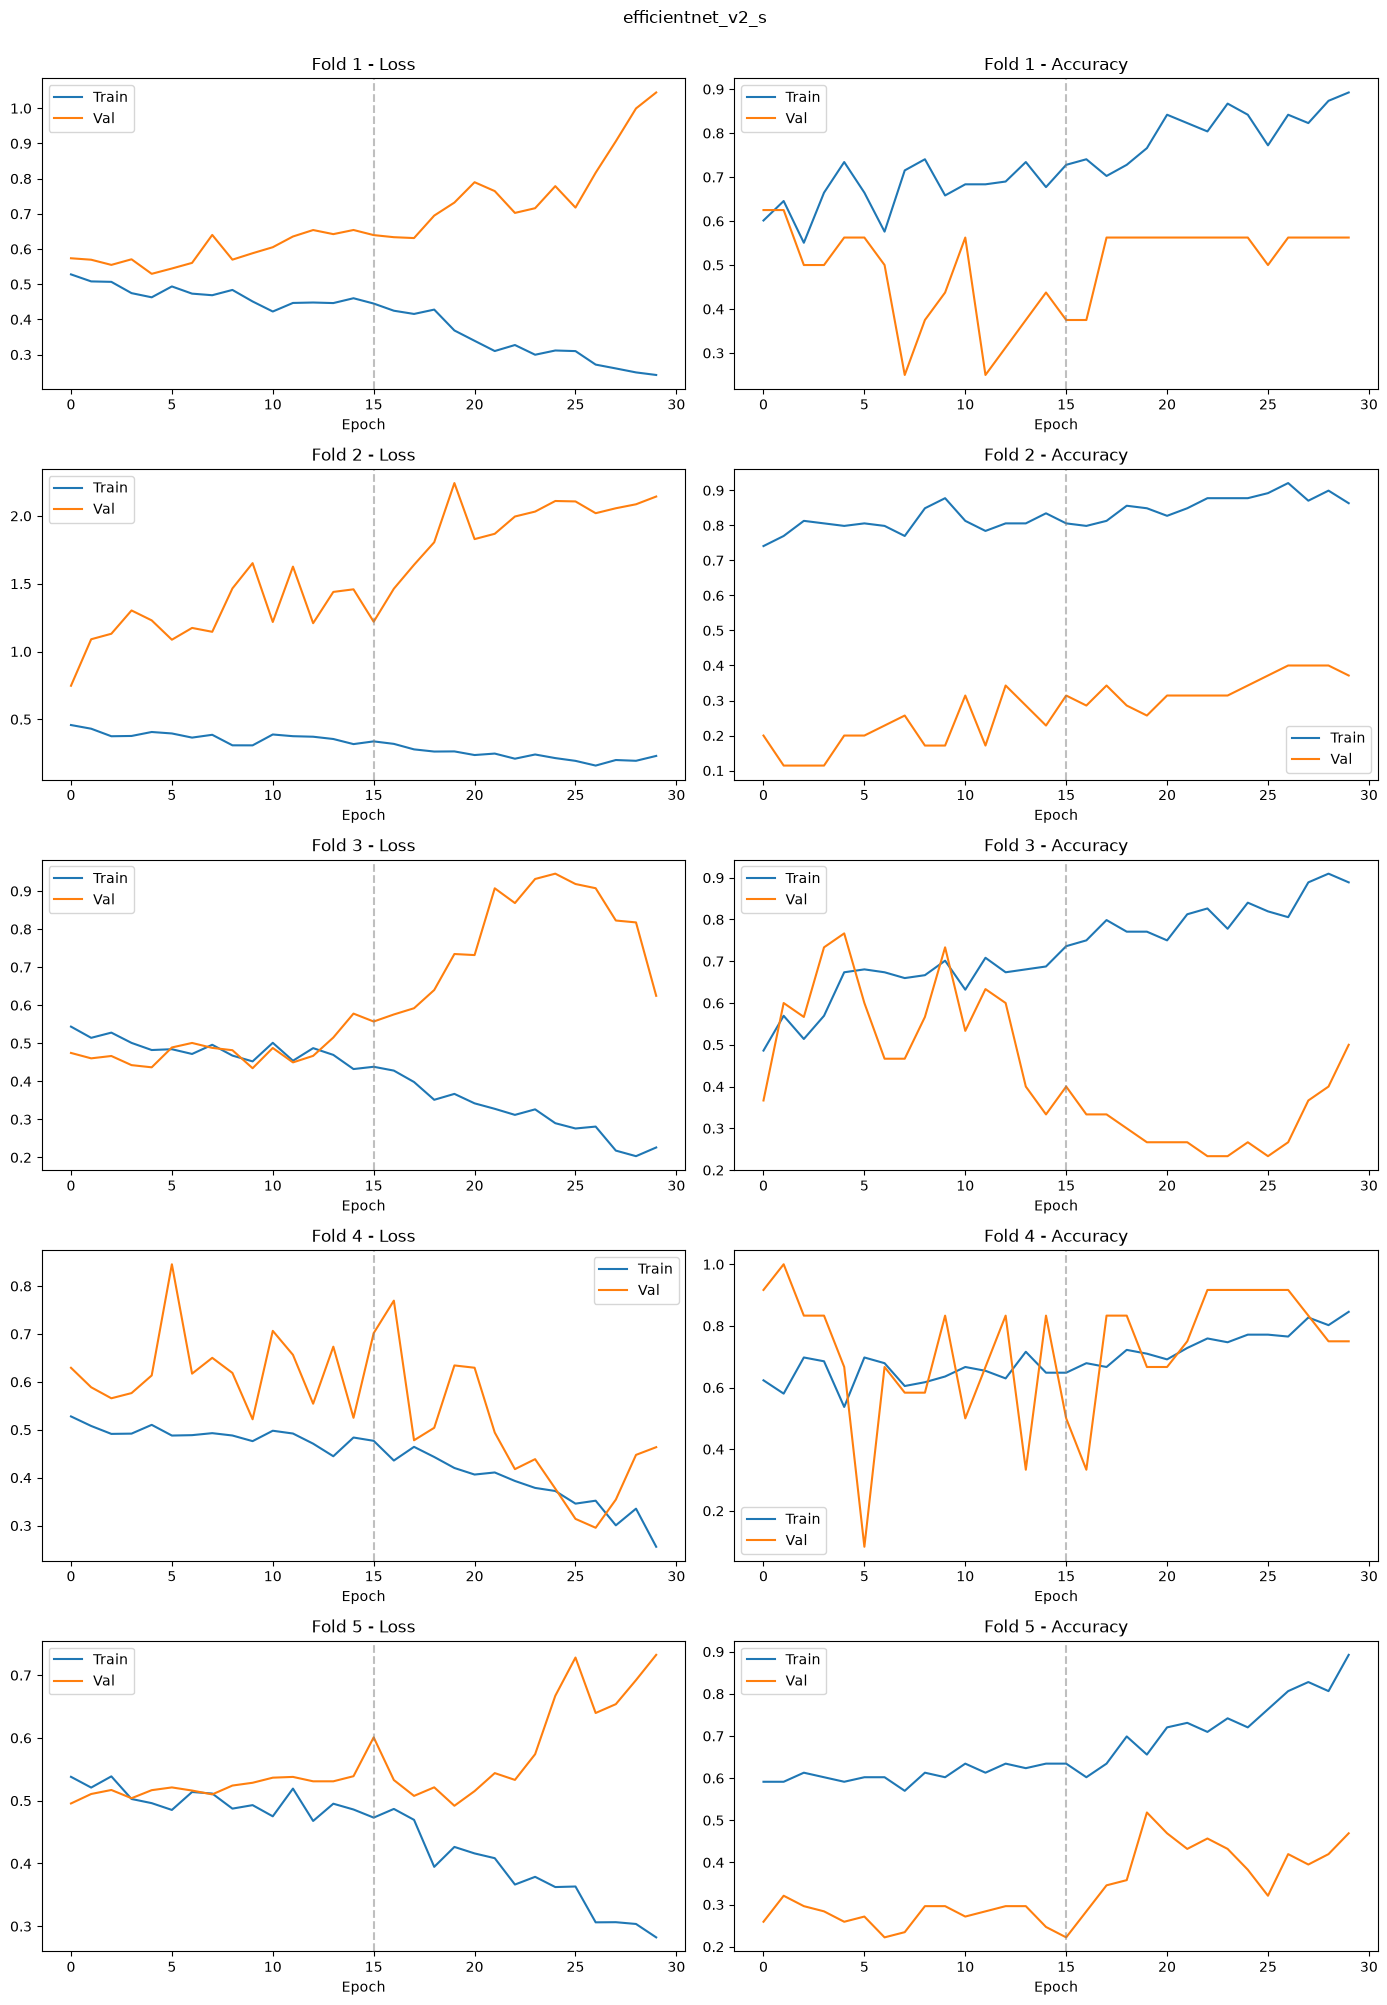

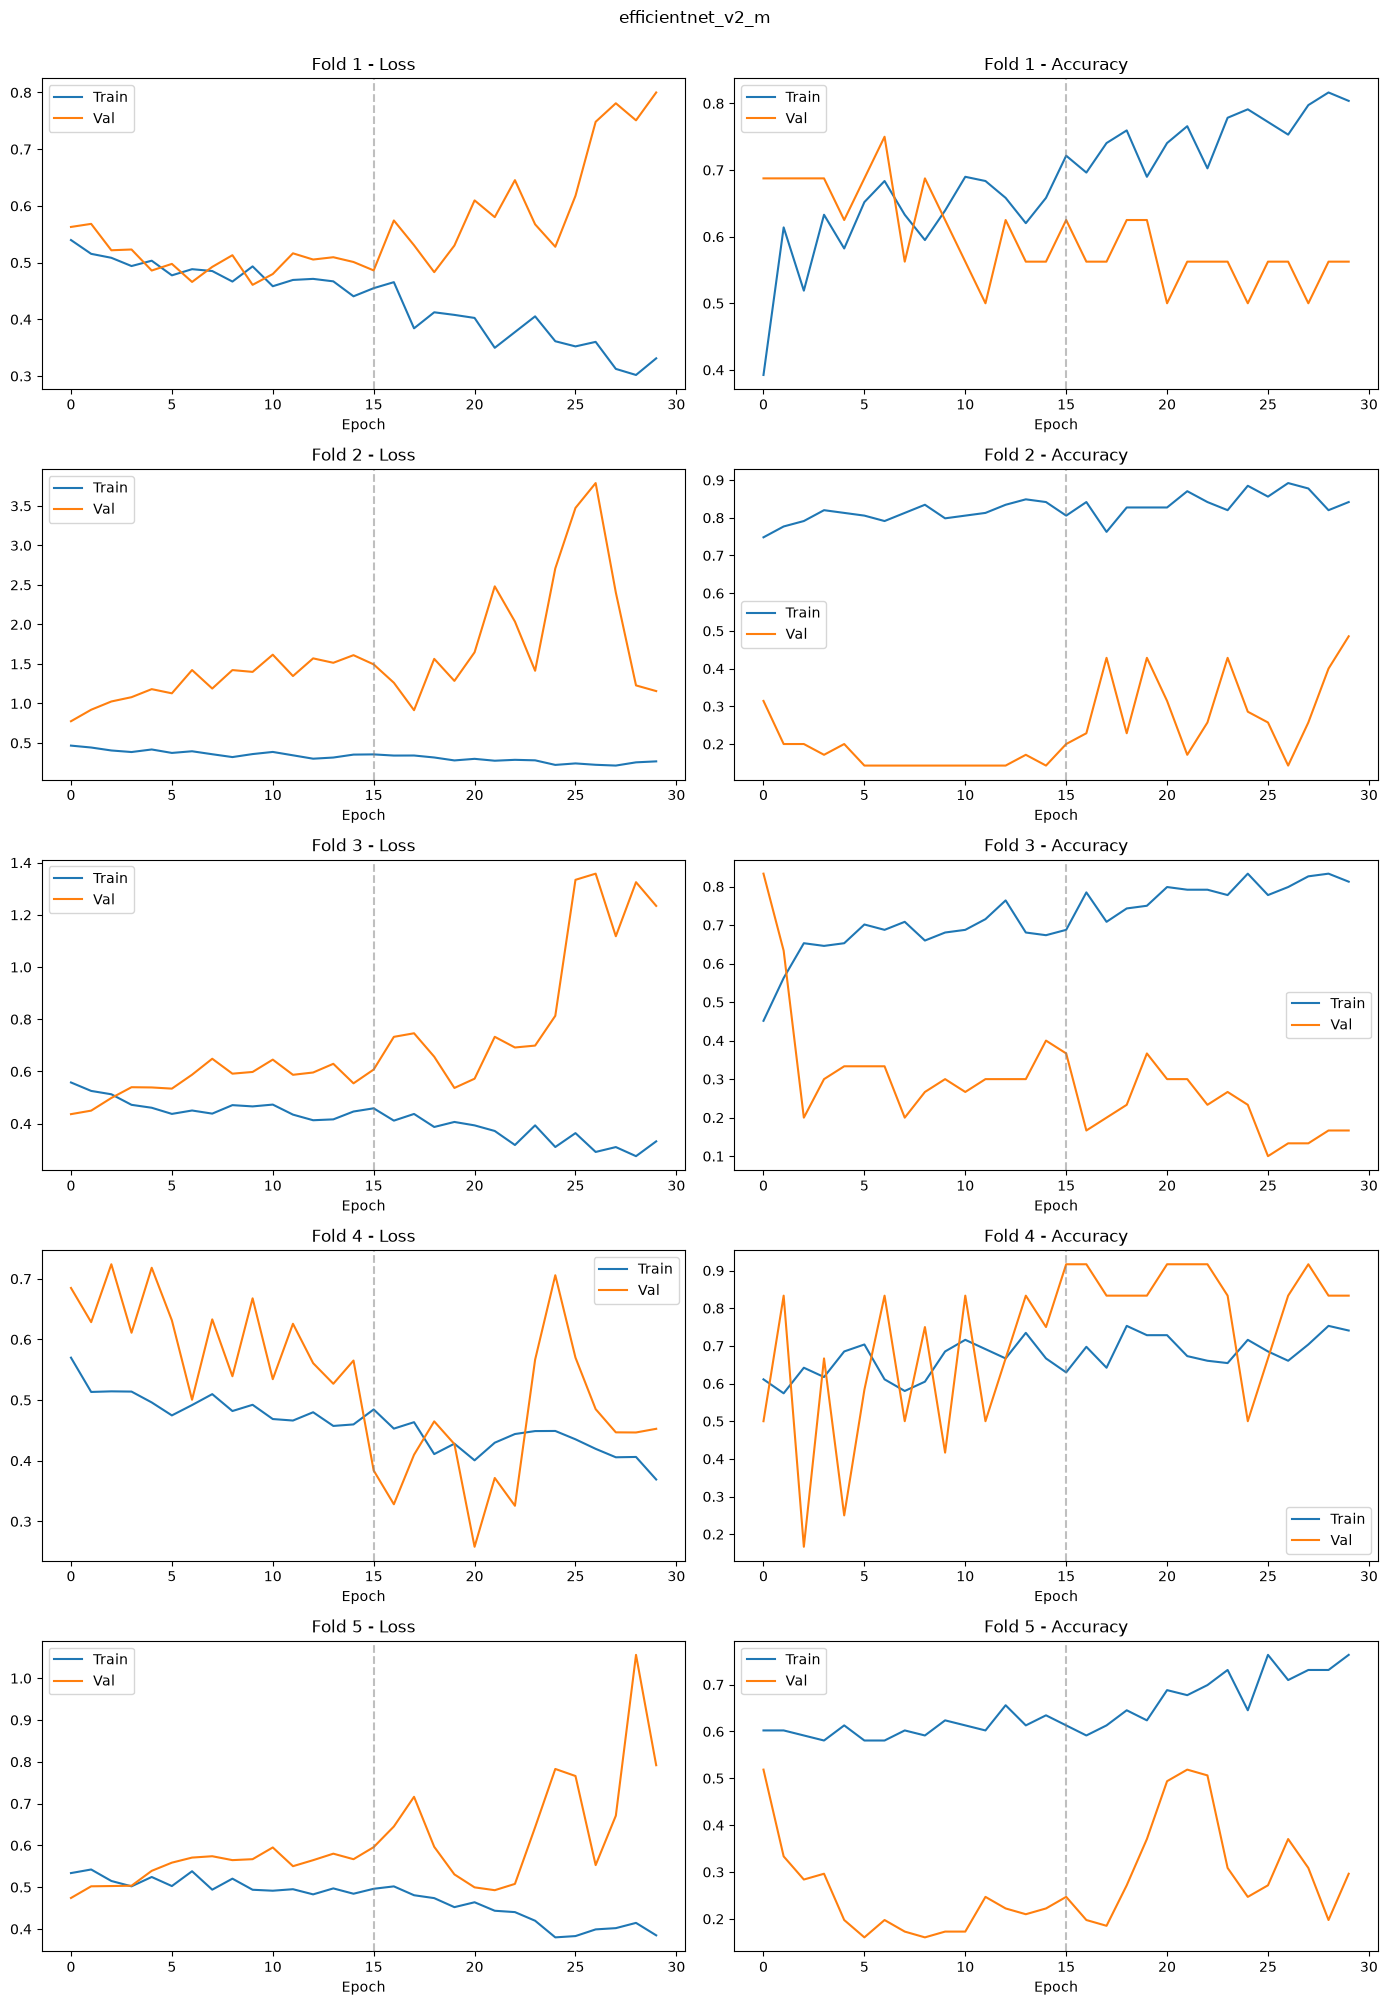

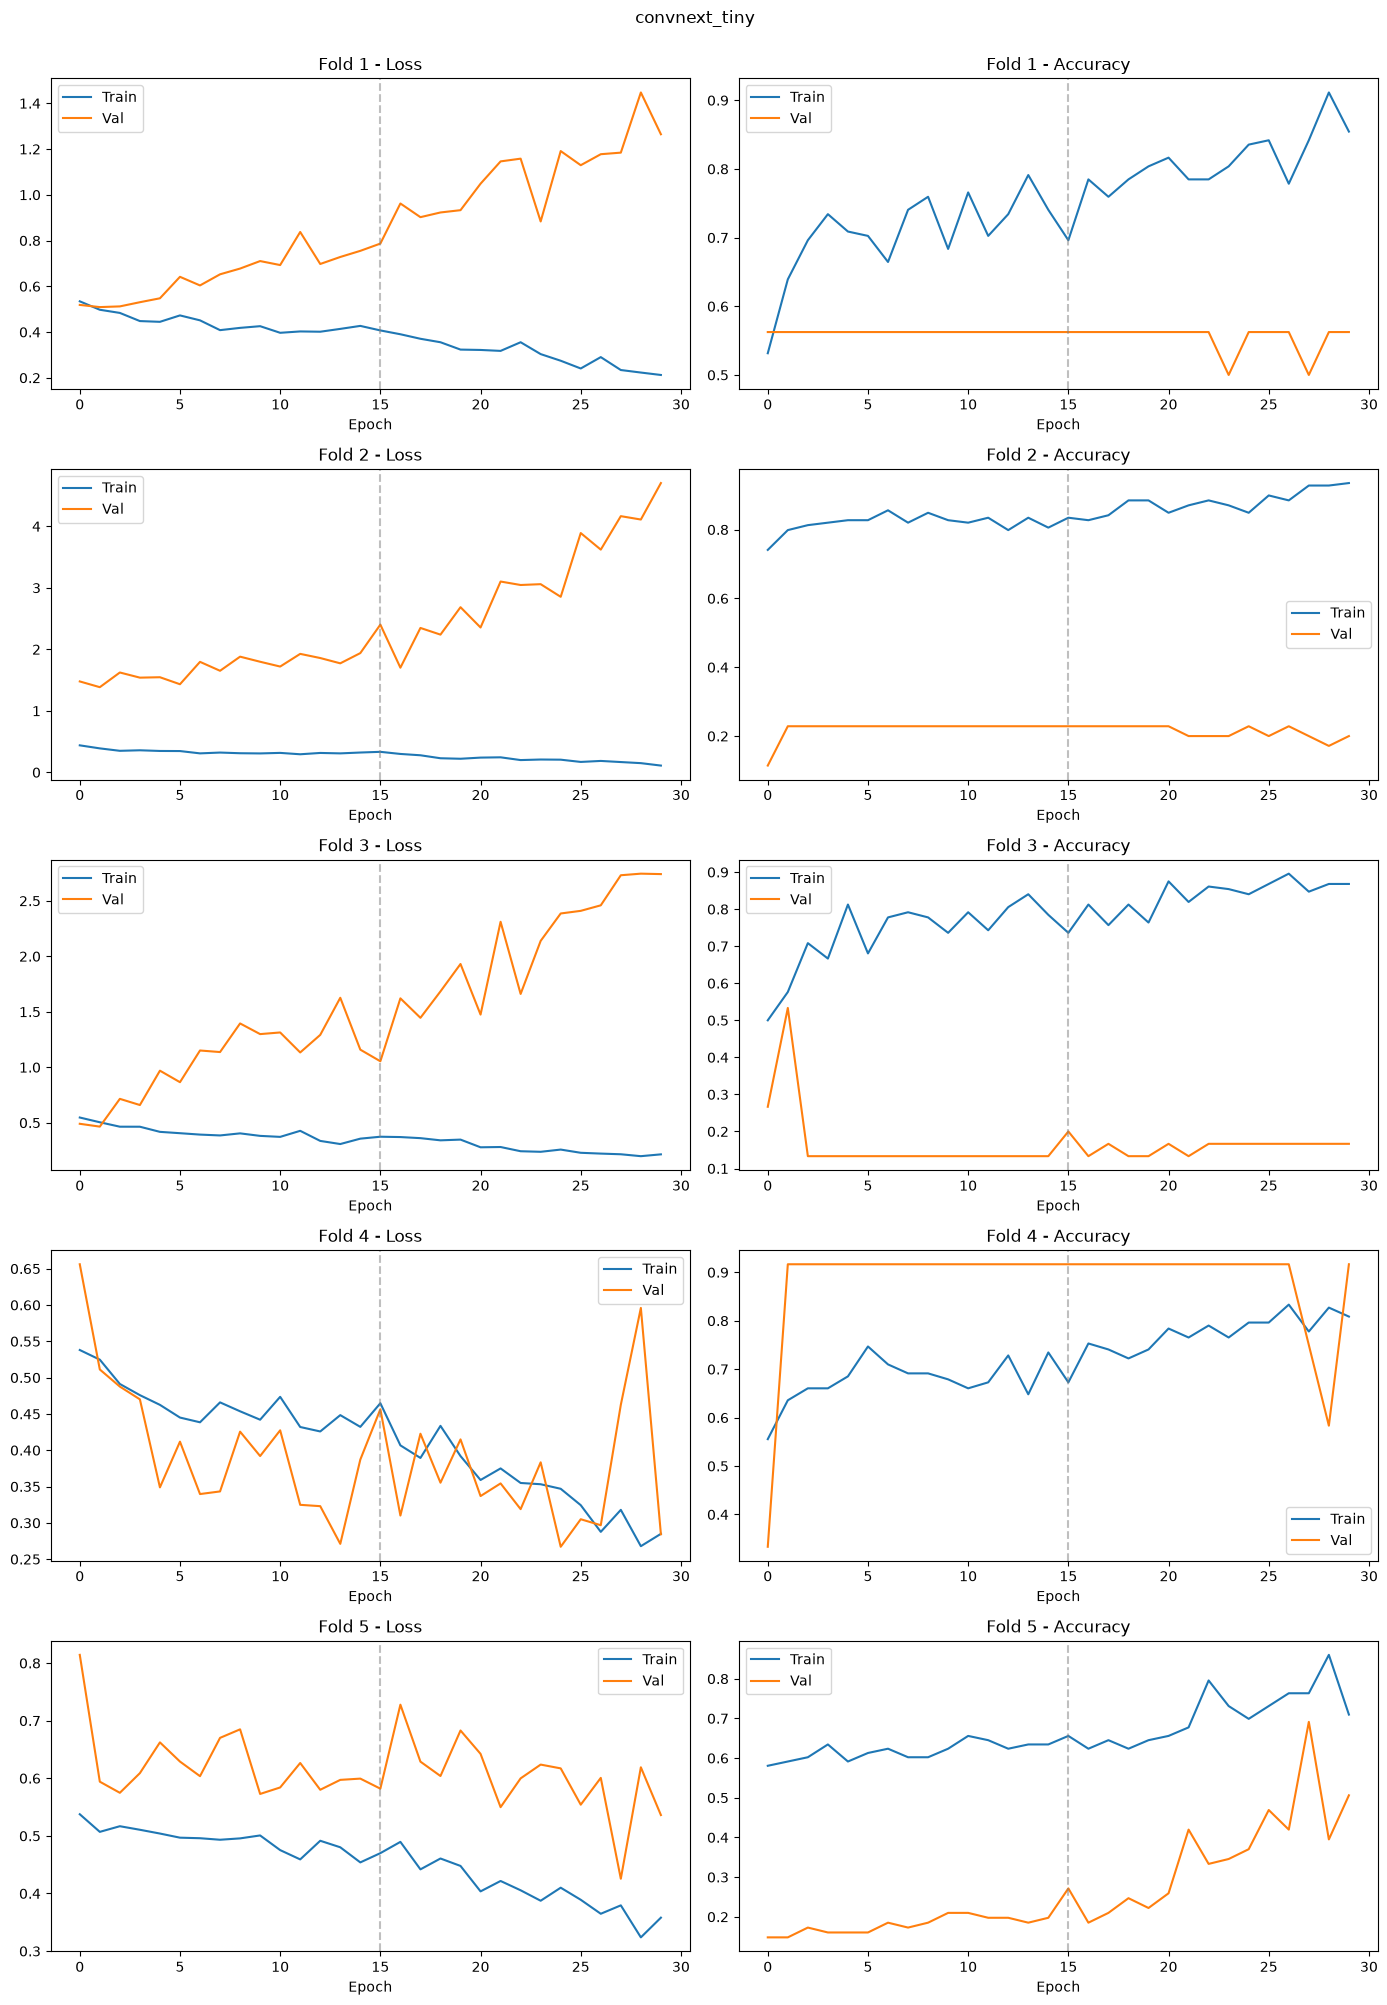

In [17]:
for name, result in results.items():
    fig, axes = plt.subplots(N_FOLDS, 2, figsize=(14, 4 * N_FOLDS))
    fig.suptitle(name, y=1.0)

    for i, history in enumerate(result["histories"]):
        axes[i, 0].plot(history["train_loss"], label="Train")
        axes[i, 0].plot(history["val_loss"], label="Val")
        axes[i, 0].set_title(f"Fold {i+1} - Loss")
        axes[i, 0].legend()
        axes[i, 0].set_xlabel("Epoch")
        axes[i, 0].axvline(x=UNFREEZE_AT_EPOCH, color='gray', linestyle='--', alpha=0.5, label='Unfreeze')

        axes[i, 1].plot(history["train_acc"], label="Train")
        axes[i, 1].plot(history["val_acc"], label="Val")
        axes[i, 1].set_title(f"Fold {i+1} - Accuracy")
        axes[i, 1].legend()
        axes[i, 1].set_xlabel("Epoch")
        axes[i, 1].axvline(x=UNFREEZE_AT_EPOCH, color='gray', linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"training_curves_{name}.png", dpi=150, bbox_inches='tight')
    plt.show()

## 9. Overall evaluation

Confusion matrix and classification report on the whole dataset (each image was predicted exactly once through the K-Fold).

efficientnet_v2_s - Classification Report (aggregated over the 5 folds):

              precision    recall  f1-score   support

   Incorrect       0.38      0.54      0.44        67
     Correct       0.61      0.45      0.52       107

    accuracy                           0.48       174
   macro avg       0.49      0.49      0.48       174
weighted avg       0.52      0.48      0.49       174

efficientnet_v2_m - Classification Report (aggregated over the 5 folds):

              precision    recall  f1-score   support

   Incorrect       0.35      0.70      0.46        67
     Correct       0.47      0.17      0.25       107

    accuracy                           0.37       174
   macro avg       0.41      0.43      0.36       174
weighted avg       0.42      0.37      0.33       174

convnext_tiny - Classification Report (aggregated over the 5 folds):

              precision    recall  f1-score   support

   Incorrect       0.34      0.54      0.42        67
     Correct       

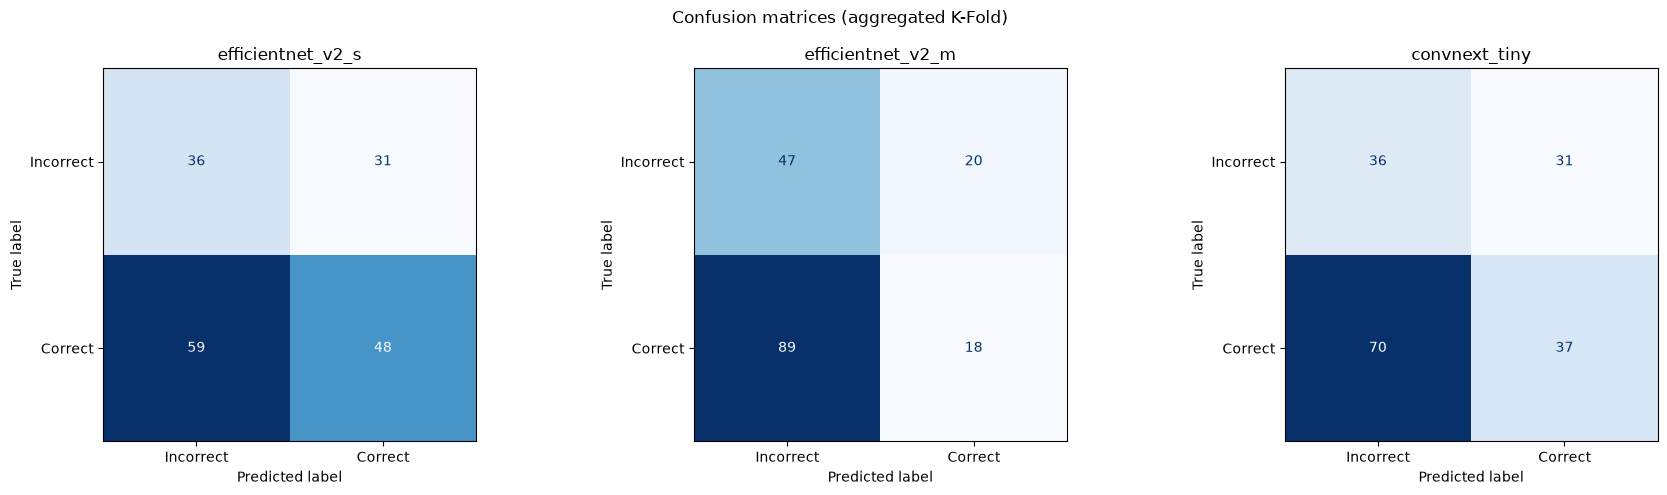

In [18]:
fig, axes = plt.subplots(1, len(results), figsize=(6 * len(results), 5))
for ax, (name, result) in zip(axes, results.items()):
    print(f"{name} - Classification Report (aggregated over the {N_FOLDS} folds):\n")
    print(classification_report(y, result["preds"],
                                target_names=["Incorrect", "Correct"], zero_division=0))

    cm = confusion_matrix(y, result["preds"])
    ConfusionMatrixDisplay(cm, display_labels=["Incorrect", "Correct"]).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)

fig.suptitle("Confusion matrices (aggregated K-Fold)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=150, bbox_inches='tight')
plt.show()

## 10. Predictions and model comparison

**Predictions**: one row per copy and per model, with the verdict of the model that did not see this student during training (out-of-fold prediction). This file has the same format as the predictions of the other approaches, so that they can be compared.

**Scores**: computed from these predictions, on all the data and on each subset (batch, exercise type). A subset is a row of the table, not a separate training. The **Baseline** always gives the same answer, the majority class of the whole dataset ("correct"), without looking at the image. Its balanced accuracy is therefore exactly 0.5, the chance level: a useful model must do better. (Taking the majority class of each training fold would not work here: when the students left out of a fold have almost everything correct, the rest is mostly incorrect, and the baseline would answer "incorrect" on a fold that is mostly correct.)

Models are ranked on the **macro F1** of all the data, because accuracy alone favours the majority class. With so few images, a gap of a few points between two models does not allow us to tell them apart.

In [19]:
METRIC_LABELS = {
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced accuracy",
    "f1_macro": "Macro F1",
    "recall_incorrect": "Recall (incorrect)",
}

# Out-of-fold verdicts of each model
oof_preds = {name: result["preds"] for name, result in results.items()}

# Baseline: always the same answer, the majority class of the whole dataset ("correct")
majority = int(np.mean(y) >= 0.5)
oof_preds["baseline"] = np.full(len(y), majority)

# Predictions file: one row per copy and per model
predictions = pd.concat([
    copies.assign(model=name, verdict=np.where(preds == 1, "correct", "incorrect"))
    for name, preds in oof_preds.items()
], ignore_index=True)
predictions = predictions[["student", "batch", "exercise", "type", "label", "model", "verdict"]]
predictions.to_csv(PREDICTIONS_PATH, index=False)
print(f"Predictions saved to {PREDICTIONS_PATH} ({len(predictions)} rows)")

# Scores on all the data and on each subset
subsets = {"all": np.ones(len(y), bool)}
subsets.update({f"batch {b}": (copies["batch"] == b).to_numpy() for b in sorted(copies["batch"].unique())})
subsets.update({f"type {t}": (copies["type"] == t).to_numpy() for t in sorted(copies["type"].unique())})

rows = []
for name, preds in oof_preds.items():
    for subset, mask in subsets.items():
        scores = compute_metrics(y[mask], preds[mask])
        rows.append({"model": name, "subset": subset, "copies": int(mask.sum()),
                     **{label: round(scores[key], 3) for key, label in METRIC_LABELS.items()}})
metrics = pd.DataFrame(rows)
metrics.to_csv(OUTPUT_DIR / "metrics.csv", index=False, encoding="utf-8-sig")

display(metrics[metrics["subset"] == "all"].set_index("model"))
display(metrics.pivot(index="subset", columns="model", values="Balanced accuracy"))

best_model_name = max(MODEL_NAMES, key=lambda name: compute_metrics(y, oof_preds[name])["f1_macro"])
print(f"Best macro F1: {best_model_name}")

Predictions saved to ..\..\outputs\predictions\classifier.csv (696 rows)


,subset,copies,Accuracy,Balanced accuracy,Macro F1,Recall (incorrect)
model,,,,,,
efficientnet_v2_s,all,174,0.483,0.493,0.480,0.537
efficientnet_v2_m,all,174,0.374,0.435,0.356,0.701
convnext_tiny,all,174,0.420,0.442,0.420,0.537
baseline,all,174,0.287,0.267,0.271,0.179


model,baseline,convnext_tiny,efficientnet_v2_m,efficientnet_v2_s
subset,,,,
all,0.267,0.442,0.435,0.493
batch 1,0.294,0.308,0.350,0.386
batch 2,0.500,0.482,0.482,0.492
type circle,0.125,0.375,0.000,0.125
type colour,0.375,0.582,0.457,0.538
type link,0.434,0.399,0.434,0.535
type tick,0.233,0.333,0.267,0.433
type trace,0.500,0.500,0.500,0.500
type write_number,0.283,0.246,0.363,0.339


Best macro F1: efficientnet_v2_s


## 11. Training the final model

We retrain **only the best model** on **all** the data (no validation split) to get the best possible model for deployment. The K-Fold gave the performance estimate, this model is the one we keep. It is saved in `models/` (not versioned).

In [20]:
print(f"Training the final model ({best_model_name}) on all the data...")
set_seed()

full_ds = ExamDataset(X, y, augment=True)
full_loader = DataLoader(full_ds, batch_size=BATCH_SIZE, shuffle=True)

final_model = create_model(best_model_name, unfreeze_last_n=0)
criterion = make_criterion()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, final_model.parameters()), lr=LEARNING_RATE)

for epoch in range(EPOCHS):
    if epoch == UNFREEZE_AT_EPOCH:
        print(f"  → Unfreezing the last 2 blocks")
        for param in final_model.features[-2:].parameters():
            param.requires_grad = True
        optimizer = optim.Adam(filter(lambda p: p.requires_grad, final_model.parameters()), lr=LEARNING_RATE * 0.1)

    train_loss, train_acc = train_one_epoch(final_model, full_loader, criterion, optimizer)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"  Epoch {epoch+1:2d}/{EPOCHS} | Loss: {train_loss:.4f} | Acc: {train_acc:.3f}")

final_path = MODELS_DIR / f"classifier_{best_model_name}.pth"
torch.save(final_model.state_dict(), final_path)
print(f"\nFinal model saved to {final_path}")

Training the final model (efficientnet_v2_s) on all the data...
  Epoch  1/30 | Loss: 0.5235 | Acc: 0.517
  Epoch  5/30 | Loss: 0.4867 | Acc: 0.621
  Epoch 10/30 | Loss: 0.4665 | Acc: 0.632
  Epoch 15/30 | Loss: 0.4609 | Acc: 0.724
  → Unfreezing the last 2 blocks
  Epoch 20/30 | Loss: 0.3793 | Acc: 0.764
  Epoch 25/30 | Loss: 0.3015 | Acc: 0.770
  Epoch 30/30 | Loss: 0.2649 | Acc: 0.822

Final model saved to ..\..\models\classifier_efficientnet_v2_s.pth
